# Depth Estimation Comparison: MiDaS vs DPT vs ZoeDepth
.

## 1. Setup

In [13]:
!pip -q install "transformers>=4.45" timm datasets accelerate scipy pandas matplotlib opencv-python-headless h5py

In [14]:
import os, time, warnings
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

# Optional: silences the "unauthenticated requests" warning and speeds up downloads
# os.environ["HF_TOKEN"] = "hf_..."

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_IMAGES = 100          # 654 = full official NYU test set
os.makedirs("results", exist_ok=True)
print("device:", DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu130


## 2. Metrics and alignment

In [15]:
import numpy as np

MIN_D, MAX_D = 1e-3, 10.0   # NYU range (m); use 80 for KITTI

def valid_mask(gt):
    return (gt > MIN_D) & (gt < MAX_D) & np.isfinite(gt)

def align_disparity_lsq(pred_disp, gt_depth, mask):
    """MiDaS protocol: per-image least-squares scale+shift in disparity space -> depth."""
    g = 1.0 / gt_depth[mask]; p = pred_disp[mask]
    A = np.stack([p, np.ones_like(p)], 1)
    (s, t), *_ = np.linalg.lstsq(A, g, rcond=None)
    disp = np.clip(s * pred_disp + t, 1.0 / MAX_D, 1.0 / MIN_D)
    return 1.0 / disp

def align_median(pred_depth, gt_depth, mask):
    s = np.median(gt_depth[mask]) / max(np.median(pred_depth[mask]), 1e-6)
    return np.clip(pred_depth * s, MIN_D, MAX_D)

def depth_metrics(pred, gt, mask):
    p, g = np.clip(pred[mask], MIN_D, None), gt[mask]
    thr = np.maximum(p / g, g / p)
    diff = p - g
    dlog = np.log(p) - np.log(g)
    return dict(
        AbsRel=float(np.mean(np.abs(diff) / g)),
        SqRel=float(np.mean(diff ** 2 / g)),
        RMSE=float(np.sqrt(np.mean(diff ** 2))),
        RMSElog=float(np.sqrt(np.mean(dlog ** 2))),
        log10=float(np.mean(np.abs(np.log10(p) - np.log10(g)))),
        SILog=float(100 * np.sqrt(max(np.mean(dlog ** 2) - np.mean(dlog) ** 2, 0))),
        d1=float(np.mean(thr < 1.25)),
        d2=float(np.mean(thr < 1.25 ** 2)),
        d3=float(np.mean(thr < 1.25 ** 3)))

## 3. Data (Kaggle)
1. In the notebook sidebar click **Add Input** and add an NYU Depth v2 dataset (search "NYU Depth V2" on Kaggle). Any of these layouts works, detected automatically:
   - **Eigen test split** files `eigen_test_rgb.npy` + `eigen_test_depth.npy` (654 images, metres, best choice)
   - **Labeled `.mat`** `nyu_depth_v2_labeled.mat` (1449 images, metres)
   - **`nyu2_test`** folder of `*_colors.png` + `*_depth.png` (654 images; depth is stored as 8-bit, see the note in the loader)
2. In **Settings** turn on **Internet** (model weights come from GitHub / Hugging Face) and choose a **GPU** accelerator.

All sources use the standard Eigen evaluation crop; pixels outside it are marked invalid.

In [16]:
import glob, os
N_IMAGES = min(N_IMAGES, 654)

def eigen_crop(d):
    out = np.zeros_like(d)
    if d.shape == (480, 640): out[45:471, 41:601] = d[45:471, 41:601]; return out
    return d

def find(pattern):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    return sorted(hits)

def load_nyu(n):
    samples = []
    npy_rgb, npy_d = find("eigen_test_rgb.npy"), find("eigen_test_depth.npy")
    mats = find("nyu_depth_v2_labeled.mat")
    pngs = find("*_colors.png")
    if npy_rgb and npy_d:
        print("source: eigen_test npy files")
        rgb, dep = np.load(npy_rgb[0], mmap_mode="r"), np.load(npy_d[0], mmap_mode="r")
        for i in range(min(n, len(rgb))):
            img = np.array(rgb[i]); d = np.array(dep[i]).astype(np.float32)
            if img.shape[0] == 3: img = img.transpose(1, 2, 0)             # CHW -> HWC
            if d.max() > 100: d /= 1000.0
            samples.append((img.astype(np.uint8), eigen_crop(d)))
    elif mats:
        print("source: nyu_depth_v2_labeled.mat")
        import h5py
        with h5py.File(mats[0], "r") as f:
            for i in range(min(n, f["images"].shape[0])):
                img = np.array(f["images"][i]).transpose(2, 1, 0)           # (3,W,H) -> (H,W,3)
                d = np.array(f["depths"][i]).transpose(1, 0).astype(np.float32)
                samples.append((img.astype(np.uint8), eigen_crop(d)))
    elif pngs:
        print("source: nyu2_test PNG pairs")
        for p in pngs[:n]:
            img = np.array(Image.open(p).convert("RGB"))
            raw = np.array(Image.open(p.replace("_colors", "_depth")))
            # 8-bit PNG (DenseDepth/Kaggle format): 0-255 -> 0-10 m ; 16-bit: millimetres
            d = raw.astype(np.float32) / 255.0 * 10.0 if raw.dtype == np.uint8 else raw.astype(np.float32) / 1000.0
            samples.append((img, eigen_crop(d)))
    else:
        raise FileNotFoundError("No NYU files under /kaggle/input. Click 'Add Input' and add an NYU Depth v2 dataset. "
                                "Found: " + str(glob.glob('/kaggle/input/*')))
    return samples

DATA = load_nyu(N_IMAGES)
img0, d0 = DATA[0]
print(len(DATA), "images | img", img0.shape, img0.dtype, "| depth (valid) %.2f - %.2f m" % (d0[d0 > 0].min(), d0.max()))

source: nyu2_test PNG pairs
100 images | img (480, 640, 3) uint8 | depth (valid) 1.80 - 3.62 m


## 4. Models

In [17]:
class MiDaS:
    name, kind = "MiDaS v2.1", "disp"
    def __init__(self):
        self.m = torch.hub.load("intel-isl/MiDaS", "MiDaS").to(DEVICE).eval()
        self.tf = torch.hub.load("intel-isl/MiDaS", "transforms").default_transform
    @torch.no_grad()
    def __call__(self, img):
        out = self.m(self.tf(img).to(DEVICE))
        out = F.interpolate(out.unsqueeze(1), size=img.shape[:2], mode="bicubic", align_corners=False)
        return out.squeeze().float().cpu().numpy()
    def n_params(self): return sum(p.numel() for p in self.m.parameters())

class HFDepth:
    def __init__(self, name, repo, kind):
        from transformers import AutoImageProcessor, AutoModelForDepthEstimation
        self.name, self.kind, self.repo = name, kind, repo
        self.proc = AutoImageProcessor.from_pretrained(repo)
        self.m = AutoModelForDepthEstimation.from_pretrained(repo).to(DEVICE).eval()
    @torch.no_grad()
    def __call__(self, img):
        H, W = img.shape[:2]
        inp = self.proc(images=Image.fromarray(img), return_tensors="pt").to(DEVICE)
        out = self.m(**inp)
        if "zoe" in self.repo.lower():
            try:
                r = self.proc.post_process_depth_estimation(out, source_sizes=[(H, W)])
                return r[0]["predicted_depth"].squeeze().float().cpu().numpy()
            except Exception:
                pass
        d = F.interpolate(out.predicted_depth.unsqueeze(1), size=(H, W), mode="bicubic", align_corners=False)
        return d.squeeze().float().cpu().numpy()
    def n_params(self): return sum(p.numel() for p in self.m.parameters())

MODELS = {m.name: m for m in [
    MiDaS(),
    HFDepth("DPT-Large",  "Intel/dpt-large",    "disp"),
    HFDepth("ZoeDepth-N", "Intel/zoedepth-nyu", "depth"),
]}
print(list(MODELS))

The repository intel-isl_MiDaS does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)? y


Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip
Loading weights:  None
Downloading: "https://github.com/facebookresearch/WSL-Images/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://download.pytorch.org/models/ig_resnext101_32x8-c38310e5.pth" to /root/.cache/torch/hub/checkpoints/ig_resnext101_32x8-c38310e5.pth


100%|██████████| 340M/340M [00:04<00:00, 71.9MB/s] 


Downloading: "https://github.com/isl-org/MiDaS/releases/download/v2_1/midas_v21_384.pt" to /root/.cache/torch/hub/checkpoints/midas_v21_384.pt


100%|██████████| 403M/403M [00:02<00:00, 147MB/s] 
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


preprocessor_config.json:   0%|          | 0.00/285 [00:00<?, ?B/s]

... (7 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.38GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/553 [00:00<?, ?it/s]

['MiDaS v2.1', 'DPT-Large', 'ZoeDepth-N']


## 5. Run inference once (cached for all analyses below)

In [18]:
PRED = {n: [] for n in MODELS}
for i, (img, gt) in enumerate(DATA):
    for n, m in MODELS.items():
        PRED[n].append(m(img))
    if (i + 1) % 20 == 0: print(f"{i+1}/{len(DATA)}")

def to_depth(pred, kind, gt, mask, protocol):
    disp = pred if kind == "disp" else 1.0 / np.clip(pred, 1e-3, None)
    if protocol == "raw":    return np.clip(pred, MIN_D, MAX_D)              # metric models only
    if protocol == "median": return align_median(1/np.clip(disp, 1e-6, None), gt, mask)
    return align_disparity_lsq(disp, gt, mask)                                # "lsq"

20/100
40/100
60/100
80/100
100/100


## 6. Accuracy scores

In [19]:
rows = []
for n, m in MODELS.items():
    protos = ["lsq", "median"] + (["raw"] if m.kind == "depth" else [])
    for proto in protos:
        ms = []
        for (img, gt), p in zip(DATA, PRED[n]):
            mask = valid_mask(gt)
            ms.append(depth_metrics(to_depth(p, m.kind, gt, mask, proto), gt, mask))
        r = pd.DataFrame(ms).mean().to_dict(); r.update(Model=n, Protocol=proto); rows.append(r)

acc = pd.DataFrame(rows).set_index(["Model", "Protocol"])[
    ["AbsRel","SqRel","RMSE","RMSElog","log10","SILog","d1","d2","d3"]]
acc.round(4).to_csv("results/accuracy_all_protocols.csv")
main = acc.xs("lsq", level="Protocol")       # headline table: same protocol for all three
main.round(4).to_csv("results/accuracy_main.csv")
print("== Headline (per-image scale+shift alignment, all 3 models) =="); display(main.round(4))
print("== All protocols =="); display(acc.round(4))

== Headline (per-image scale+shift alignment, all 3 models) ==


,AbsRel,SqRel,RMSE,RMSElog,log10,SILog,d1,d2,d3
Model,,,,,,,,,
MiDaS v2.1,0.1045,0.0785,0.4266,0.1388,0.0454,13.8208,0.8975,0.9780,0.9934
DPT-Large,0.1009,0.0803,0.4305,0.1349,0.0436,13.4406,0.8980,0.9801,0.9928
ZoeDepth-N,0.0633,0.0425,0.3041,0.0931,0.0275,9.2856,0.9542,0.9878,0.9971


== All protocols ==


AbsRel   SqRel    RMSE  RMSElog   log10    SILog      d1  \
Model      Protocol                                                             
MiDaS v2.1 lsq       0.1045  0.0785  0.4266   0.1388  0.0454  13.8208  0.8975   
           median    0.1771  0.2168  0.7079   0.2146  0.0726  20.2193  0.7409   
DPT-Large  lsq       0.1009  0.0803  0.4305   0.1349  0.0436  13.4406  0.8980   
           median    0.2167  0.3564  0.9146   0.2576  0.0845  24.2147  0.6852   
ZoeDepth-N lsq       0.0633  0.0425  0.3041   0.0931  0.0275   9.2856  0.9542   
           median    0.0744  0.0459  0.3180   0.1074  0.0321  10.0726  0.9320   
           raw       0.1418  0.0905  0.4275   0.1562  0.0559  10.0662  0.8581   

                         d2      d3  
Model      Protocol                  
MiDaS v2.1 lsq       0.9780  0.9934  
           median    0.9431  0.9852  
DPT-Large  lsq       0.9801  0.9928  
           median    0.9048  0.9669  
ZoeDepth-N lsq       0.9878  0.9971  
           median    0.9867  0.9964  
           raw       0.9829  0.9954

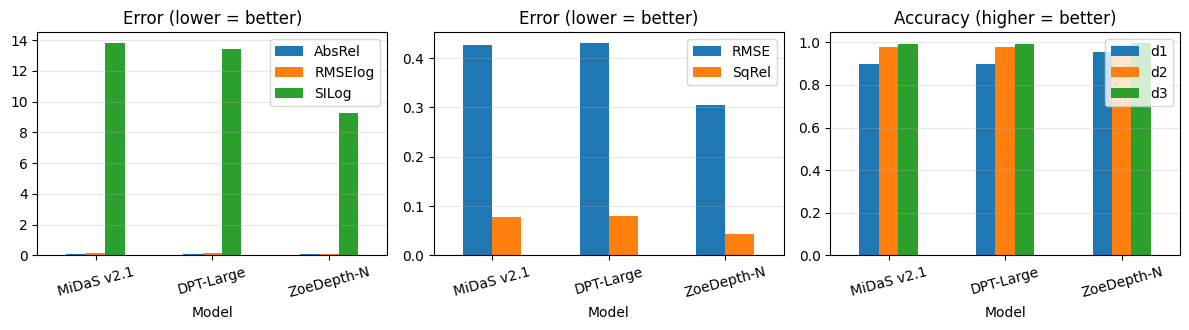

In [20]:
# Bar charts of the headline metrics
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, cols, t in zip(axs, [["AbsRel","RMSElog","SILog"], ["RMSE","SqRel"], ["d1","d2","d3"]],
                       ["Error (lower = better)", "Error (lower = better)", "Accuracy (higher = better)"]):
    main[cols].plot.bar(ax=ax, rot=15); ax.set_title(t); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig("results/accuracy_bars.png", dpi=200); plt.show()

## 7. Efficiency: parameters, latency, FPS, memory

In [21]:
def bench(m, img, reps=20):
    for _ in range(3): m(img)
    if DEVICE == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for _ in range(reps): m(img)
    if DEVICE == "cuda": torch.cuda.synchronize()
    ms = (time.time() - t0) / reps * 1000
    vram = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")
    return ms, vram

eff = []
for n, m in MODELS.items():
    ms, vram = bench(m, DATA[0][0])
    eff.append(dict(Model=n, **{"Params (M)": m.n_params()/1e6, "Latency (ms)": ms,
                                "FPS": 1000/ms, "Peak VRAM (MB)": vram}))
eff = pd.DataFrame(eff).set_index("Model"); eff.round(2).to_csv("results/efficiency.csv"); eff.round(2)

,Params (M),Latency (ms),FPS,Peak VRAM (MB)
Model,,,,
MiDaS v2.1,105.36,72.81,13.73,3167.32
DPT-Large,343.03,172.96,5.78,3238.27
ZoeDepth-N,343.79,379.20,2.64,3553.22


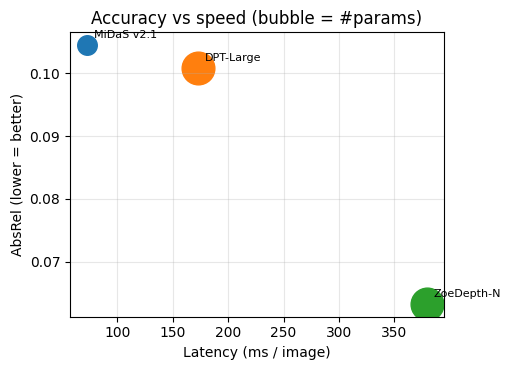

In [22]:
# Accuracy vs speed
fig, ax = plt.subplots(figsize=(5.2, 3.8))
for n in MODELS:
    ax.scatter(eff.loc[n, "Latency (ms)"], main.loc[n, "AbsRel"], s=eff.loc[n, "Params (M)"]*1.5+40)
    ax.annotate(n, (eff.loc[n, "Latency (ms)"], main.loc[n, "AbsRel"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Latency (ms / image)"); ax.set_ylabel("AbsRel (lower = better)")
ax.set_title("Accuracy vs speed (bubble = #params)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/accuracy_vs_speed.png", dpi=200); plt.show()

## 8. Error by depth range and per-image distribution

AbsRel by ground-truth depth range:


,near (0-2 m),mid (2-4 m),far (4-10 m)
Model,,,
MiDaS v2.1,0.1367,0.1131,0.2223
DPT-Large,0.1236,0.1122,0.2238
ZoeDepth-N,0.0739,0.0693,0.1576


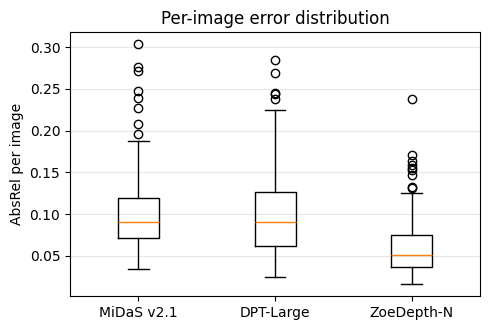

Win rate (lowest per-image AbsRel):
ZoeDepth-N    91.0
DPT-Large      5.0
MiDaS v2.1     4.0


In [23]:
bins = [(0, 2), (2, 4), (4, 10)]; names_b = ["near (0-2 m)", "mid (2-4 m)", "far (4-10 m)"]
rows = []
for n, m in MODELS.items():
    acc_b = {k: [] for k in names_b}
    for (img, gt), p in zip(DATA, PRED[n]):
        mask = valid_mask(gt); d = to_depth(p, m.kind, gt, mask, "lsq")
        for (lo, hi), k in zip(bins, names_b):
            mb = mask & (gt >= lo) & (gt < hi)
            if mb.sum() > 50: acc_b[k].append(np.mean(np.abs(d[mb] - gt[mb]) / gt[mb]))
    rows.append({"Model": n, **{k: np.mean(v) for k, v in acc_b.items()}})
rng_df = pd.DataFrame(rows).set_index("Model"); rng_df.round(4).to_csv("results/error_by_range.csv")
print("AbsRel by ground-truth depth range:"); display(rng_df.round(4))

per_img = {n: [depth_metrics(to_depth(p, m.kind, gt, valid_mask(gt), "lsq"), gt, valid_mask(gt))["AbsRel"]
               for (img, gt), p in zip(DATA, PRED[n])] for n, m in MODELS.items()}
pd.DataFrame(per_img).to_csv("results/per_image_absrel.csv", index=False)
plt.figure(figsize=(5, 3.4)); plt.boxplot(list(per_img.values()), labels=list(per_img)); plt.ylabel("AbsRel per image")
plt.title("Per-image error distribution"); plt.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig("results/per_image_boxplot.png", dpi=200); plt.show()
print("Win rate (lowest per-image AbsRel):")
W = pd.DataFrame(per_img); print((W.idxmin(axis=1).value_counts(normalize=True)*100).round(1).to_string())

## 9. Qualitative comparison

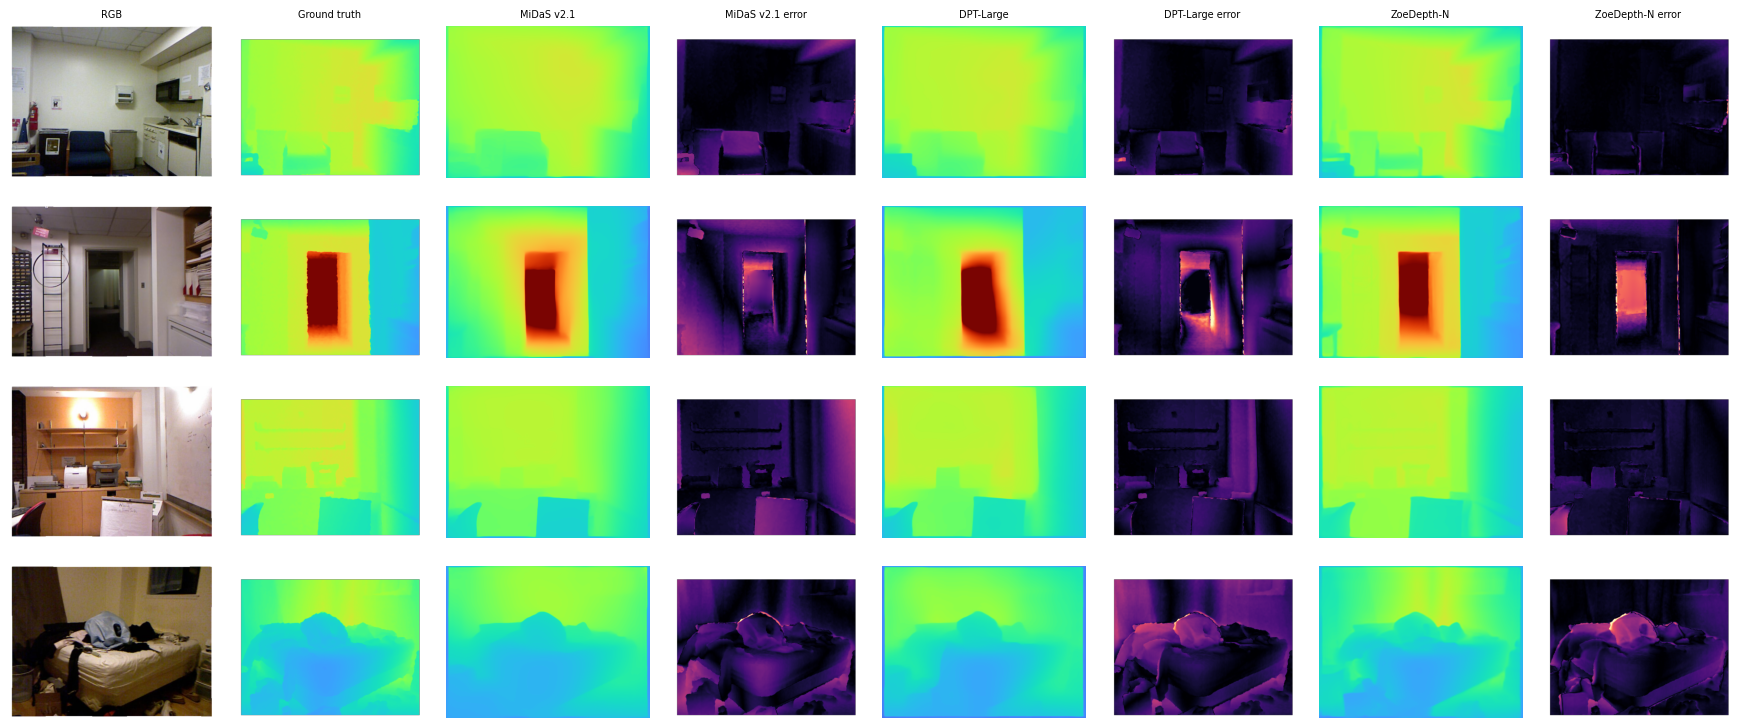

In [24]:
def colorize(d, vmin, vmax): return plt.cm.turbo(np.clip((d - vmin) / (vmax - vmin + 1e-9), 0, 1))
IDX = [i for i in [0, 7, 15, 30] if i < len(DATA)]
names = list(MODELS)
fig, axs = plt.subplots(len(IDX), 2 + 2*len(names), figsize=(2.2*(2+2*len(names)), 1.9*len(IDX)))
for r, i in enumerate(IDX):
    img, gt = DATA[i]; mask = valid_mask(gt)
    axs[r, 0].imshow(img); axs[r, 1].imshow(colorize(np.where(mask, gt, np.nan), 0, 6))
    for c, n in enumerate(names):
        d = to_depth(PRED[n][i], MODELS[n].kind, gt, mask, "lsq")
        axs[r, 2 + 2*c].imshow(colorize(d, 0, 6))
        axs[r, 3 + 2*c].imshow(np.where(mask, np.abs(d - gt) / gt, np.nan), cmap="magma", vmin=0, vmax=.5)
    if r == 0:
        for c, t in enumerate(["RGB", "Ground truth"] + sum([[n, n + " error"] for n in names], [])):
            axs[0, c].set_title(t, fontsize=7)
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("results/qualitative.png", dpi=200); plt.show()

## 10. Export
Download `results.zip` and share the CSVs to fill the report tables.

In [25]:
!zip -qr results.zip results && ls -la results

total 3236
drwxr-xr-x 2 root root    4096 Nov 14 18:10 .
drwxr-xr-x 4 root root    4096 Nov 14 18:10 ..
-rw-r--r-- 1 root root     617 Nov 14 18:09 accuracy_all_protocols.csv
-rw-r--r-- 1 root root   82782 Nov 14 18:09 accuracy_bars.png
-rw-r--r-- 1 root root     274 Nov 14 18:09 accuracy_main.csv
-rw-r--r-- 1 root root   55272 Nov 14 18:10 accuracy_vs_speed.png
-rw-r--r-- 1 root root     161 Nov 14 18:10 efficiency.csv
-rw-r--r-- 1 root root     139 Nov 14 18:10 error_by_range.csv
-rw-r--r-- 1 root root    6010 Nov 14 18:10 per_image_absrel.csv
-rw-r--r-- 1 root root   51858 Nov 14 18:10 per_image_boxplot.png
-rw-r--r-- 1 root root 3081645 Nov 14 18:10 qualitative.png
